# Self-attention from first principles

This is an untrained mathematical demonstration, not a model of RNA biology. We compare independent NumPy and PyTorch calculations with fixed random weights.

In [1]:
from pathlib import Path
import sys
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root) not in sys.path: sys.path.insert(0, str(root))
from IPython.display import display, Image, Markdown
from src.common import DATA, OUTPUT, read_json


## Queries, keys and values

For input X and learned-in-principle projections, Q = XWq, K = XWk and V = XWv. Here the weights stay random. The output is softmax(QKᵀ / √dₖ)V. Subtracting the row maximum before exponentiation preserves softmax probabilities and avoids overflow.

In [2]:
import numpy as np
from src.attention import encode_sequence, projections, self_attention, torch_self_attention
sequence = 'ACGUACGUACGGCUA'
X = encode_sequence(sequence)
Q, K, V = projections(X)
weights, output = self_attention(X)
tw, to = torch_self_attention(X)
print('Shapes:', X.shape, Q.shape, K.shape, V.shape, weights.shape, output.shape)
np.testing.assert_allclose(weights.sum(axis=1), 1)
np.testing.assert_allclose(weights, tw)
np.testing.assert_allclose(output, to)
print('Rows sum to one; NumPy and PyTorch agree.')

Shapes: (15, 8) (15, 8) (15, 8) (15, 8) (15, 15) (15, 8)
Rows sum to one; NumPy and PyTorch agree.


## Three-position hand calculation

Let Q = K = V = [[1, 0], [0, 1], [1, 1]]. For the first query, scaled scores are [1/√2, 0, 1/√2]. Their exponentials are approximately [2.028, 1, 2.028], whose sum is 5.056. The first attention row is therefore approximately [0.401, 0.198, 0.401], and its output is approximately [0.802, 0.599].

In [3]:
toy = np.array([[1., 0.], [0., 1.], [1., 1.]])
scores = toy @ toy.T / np.sqrt(2)
a = np.exp(scores - scores.max(axis=1, keepdims=True))
a /= a.sum(axis=1, keepdims=True)
print('First row:', a[0])
print('First output:', (a @ toy)[0])

First row: [0.40111209 0.19777581 0.40111209]
First output: [0.80222419 0.59888791]


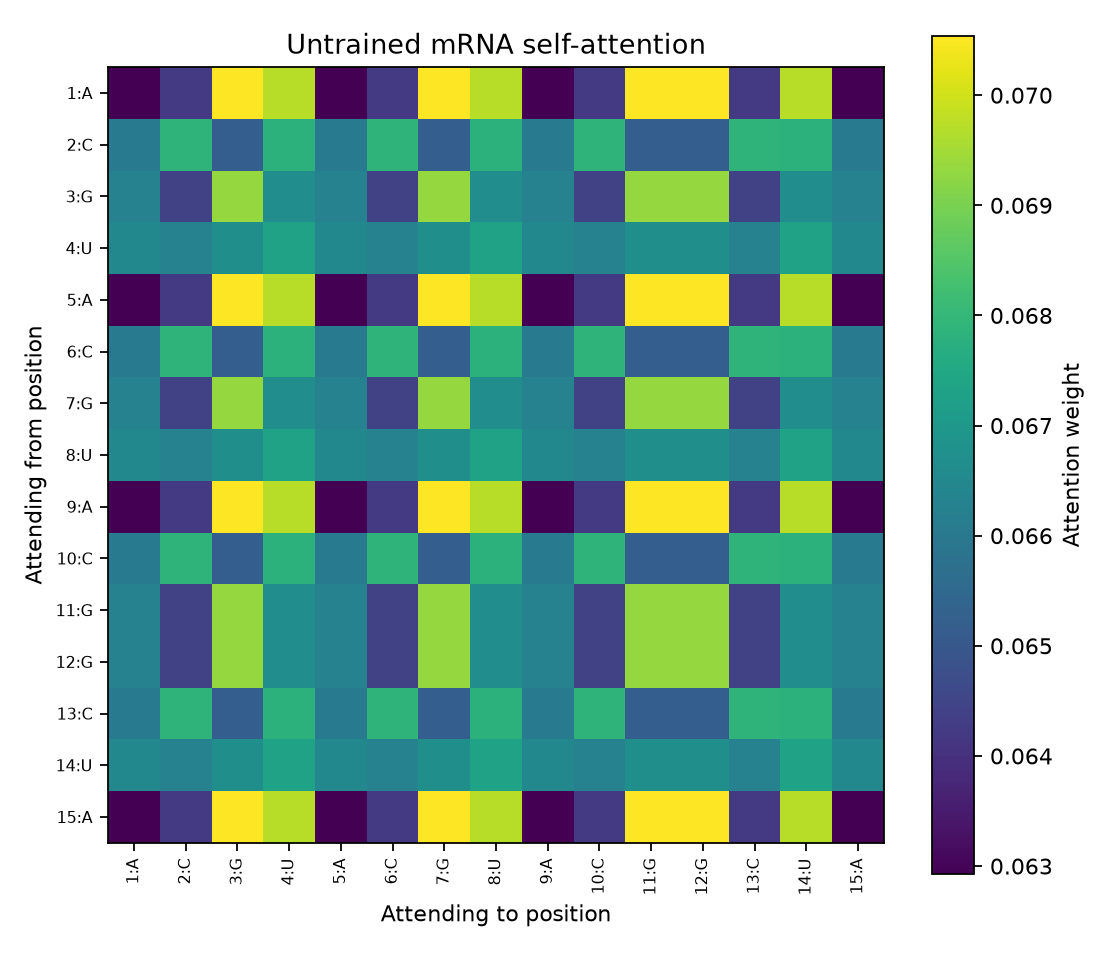

In [4]:
display(Image(filename=str(OUTPUT / 'figures/attention_heatmap.png')))

In [5]:
from src.portfolio import attention_explanation
display(Markdown(attention_explanation()))

Each nucleotide starts as an eight-dimensional vector from a fixed random embedding table. Stacking these vectors produces a sequence-length by eight input matrix. Three independently initialized projection matrices transform that input into queries Q, keys K, and values V. A query describes what a position matches against, a key describes the representation it offers for matching, and a value is the information mixed into the output. These are mathematical roles in this toy computation, not measured biological properties.

Multiplying Q by the transpose of K gives one score for every ordered pair of positions. Dividing those scores by the square root of the key dimension controls their scale. For numerical stability, the implementation subtracts each row's largest score before exponentiating. Row-wise softmax then makes every weight nonnegative and makes each row sum to one. Multiplying this weight matrix by V yields a weighted combination of value vectors for each position.

The heatmap displays those weights: a row is an attending position and a column is a position being attended to. Repeated bases have identical rows because this example has no positional encoding. The weights are untrained and nearly uniform, so their visual pattern does not establish RNA structure, sequence function, or biological interactions. A separate PyTorch calculation checks the NumPy implementation using the same projections.

Observed strongest base matches: A→G (0.07054); C→C (0.06787); G→G (0.06932); U→U (0.06732). These preferences reflect the fixed random projections, not learned biology.